# Probabilistic Graphical Models: Markov Networks and Exact Inference

> **Who is this for:** you have met Bayesian networks, d-separation and variable elimination in [`classical_ai/09`](../../00_AI_Fundamentals/classical_ai/09_uncertain_knowledge_and_reasoning.ipynb) and want the MS-level treatment found in a Probabilistic Graphical Models course (Stanford CS228, CMU 10-708): undirected models, factor graphs, the cost of exact inference, belief propagation, conditional random fields, and learning a network from data.
>
> **What you will learn:**
> - **Markov networks** (undirected models): potentials, the **partition function** and the **Gibbs distribution**, on the classic "misconception" example
> - Reading **conditional independence** off a graph: the **d-separation** ("Bayes ball") algorithm implemented and verified numerically against random distributions; **Markov blankets**; the **I-map** idea
> - A small **`Factor`** class (product, marginalise, reduce) that powers every exact algorithm
> - **Variable elimination** and how much the **elimination order** costs; **treewidth** and the min-degree / min-fill heuristics
> - **Belief propagation** (sum-product): exact on trees, approximate ("loopy") on a grid MRF used to **denoise an image** (Ising model)
> - **Max-product / Viterbi** for MAP inference, with the link to HMMs
> - A **linear-chain CRF** from scratch: forward–backward, the log-likelihood gradient (checked by finite differences), training with L-BFGS on a toy named-entity task
> - **Parameter learning** for Bayesian networks (maximum likelihood and Dirichlet smoothing) and **structure learning** by BIC hill-climbing
>
> **Prerequisites:** [`classical_ai/09` Uncertain knowledge and reasoning](../../00_AI_Fundamentals/classical_ai/09_uncertain_knowledge_and_reasoning.ipynb) (Bayes nets, d-separation basics, enumeration and VE); [probability](../../14_Mathematics/03_probability.ipynb) (conditional probability, independence); [logistic regression](../01_supervised/02_logistic_regression.ipynb) (log-likelihood and gradients); [graph theory](../../14_Mathematics/discrete_math/03_graph_theory.ipynb) helps.
>
> **Time needed:** about 4 hours.
>
> **Runs on:** CPU, no API key, no internet. The whole notebook runs in about 1–2 minutes.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep. It follows Koller & Friedman, *Probabilistic Graphical Models* (2009), chapters 3–4, 9–11, 17–18, and Bishop, *Pattern Recognition and Machine Learning* (2006), chapter 8.

## Explained simply

Real problems involve many uncertain things at once: symptoms and diseases, words and their meanings, pixels and the objects they show. Writing down the probability of *every* combination is hopeless: just 30 yes/no variables have over a billion combinations. A **graphical model** draws a picture with one dot per variable and a line between variables that *directly* influence each other. The missing lines are the important part: they say what does **not** directly matter, which lets us store and compute probabilities piece by piece.

Two everyday pictures:
- **Gossip in a friendship network.** What you hear depends directly only on your friends. If you know everything your friends said, the rest of the school tells you nothing new. That is a **Markov blanket**, and it is exactly what an undirected graphical model encodes.
- **Spell-checking a sentence.** Whether a word is a name or a place depends on its neighbours ("lives in ___" suggests a place). A **conditional random field** scores whole label sequences using such neighbour-to-neighbour links, and dynamic programming finds the best labeling quickly.

**Tiny example.** Four friends sit in a ring: Alice–Bob–Charles–Debbie–Alice. Each pair of neighbours tends to agree on an answer (yes/no). With 4 people there are $2^4 = 16$ possible answer patterns. Give each pattern a score by multiplying a number for each neighbouring pair (say 10 if they agree, 1 if not). The pattern "all yes" scores $10 \times 10 \times 10 \times 10 = 10{,}000$. A pattern where only Alice disagrees with her two neighbours scores $1 \times 10 \times 10 \times 1 = 100$. Dividing each score by the total over all 16 patterns turns scores into probabilities. That total is the **partition function**.

**In one line**

| Concept | Simple meaning | Where you see it in real life/AI |
|---|---|---|
| Graphical model | a graph whose missing edges say "these don't directly affect each other" | medical diagnosis systems, fault detection, spam filters |
| Inference (variable elimination, belief propagation) | answering "how likely is X given what I saw?" by passing local messages | error-correcting codes in phones and Wi-Fi (LDPC decoding), image denoising |
| CRF / Viterbi | scoring whole label sequences and picking the best | named-entity recognition, speech recognition, gene finding |

### How this notebook is different from `classical_ai/09`
[`classical_ai/09`](../../00_AI_Fundamentals/classical_ai/09_uncertain_knowledge_and_reasoning.ipynb) introduces Bayesian networks, d-separation rules, enumeration, a first variable-elimination example, sampling and HMMs. Here we:
- add **undirected** models and factor graphs;
- implement d-separation as an *algorithm* and test it against thousands of numerical independence checks;
- build a general `Factor` toolkit;
- **measure** how elimination order and treewidth drive cost;
- implement belief propagation (exact and loopy) and a trainable CRF;
- learn networks from data.

Approximate inference by EM, variational methods and Gibbs sampling continues in the next notebook.

## Table of contents
1. From directed to undirected models: potentials, partition function, Gibbs distribution
2. Conditional independence: d-separation (Bayes ball), Markov blankets, I-maps
3. Factors: a tiny library for exact inference
4. Variable elimination, elimination order and treewidth
5. Belief propagation: exact on trees, loopy on a grid (image denoising)
6. Max-product and Viterbi: MAP inference
7. Linear-chain conditional random fields
8. Learning Bayesian networks: parameters and structure
9. Summary table
10. How this connects to modern AI
11. Recap, practice problems, further reading

In [1]:
# Standard setup used throughout this notebook
import random, math, time, timeit, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)          # reproducible random numbers (Python)
np.random.seed(42)       # reproducible random numbers (NumPy)

# One consistent, colour-blind-friendly palette for every chart in this module
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.titleweight": "bold", "figure.dpi": 100,
})
pd.set_option("display.width", 140)
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)

import itertools
from collections import Counter, defaultdict
import networkx as nx
from networkx.algorithms.approximation import treewidth_min_degree, treewidth_min_fill_in
from scipy.optimize import minimize
from scipy.special import logsumexp
rng = np.random.default_rng(0)

Python 3.12.3 | numpy 2.4.6 | pandas 2.3.3


## 1. From directed to undirected models

A Bayesian network uses arrows and conditional probability tables. A Markov network uses plain lines and "compatibility scores" between neighbours.

**Recap: Bayesian networks (BNs).** A directed acyclic graph (DAG) plus a conditional probability table (CPT) per node:

$$P(X_1, \dots, X_n) = \prod_i P(X_i \mid \mathrm{Pa}(X_i)).$$

Arrows suggest causal direction; each factor is already normalised.

**Markov networks** (Markov random fields, MRFs) use an **undirected** graph. For each clique $c$ (a fully connected set of nodes) we choose a non-negative **potential** (factor) $\phi_c(x_c)$, a "compatibility score" that is **not** a probability. The **Gibbs distribution** is

$$P(x) = \frac1Z\prod_c\phi_c(x_c), \qquad Z = \sum_{x}\prod_c\phi_c(x_c).$$

$Z$ is the **partition function**. It sums over *all* joint assignments, which is why computing it is the hard part: #P-hard in general. With energies $E_c = -\log\phi_c$, this reads $P(x) \propto e^{-\sum_c E_c(x_c)}$, the Boltzmann distribution from physics.

| | Bayesian network | Markov network |
|---|---|---|
| graph | directed, acyclic | undirected |
| local parameters | CPTs $P(X \mid \mathrm{Pa})$, normalised | potentials $\phi_c \ge 0$, unnormalised |
| normalisation | automatic ($Z = 1$) | global $Z$ needed |
| natural for | causal / generative stories | symmetric interactions (pixels, spins, social ties) |
| independence reading | d-separation | graph separation |

**The misconception example** (Koller & Friedman, §4.1). Four students study in pairs around a ring: Alice–Bob, Bob–Charles, Charles–Debbie, Debbie–Alice. $X = 1$ means the student holds a misconception. Each pair's potential rewards agreement, except Charles–Debbie, who like to disagree:

| $\phi_1(A, B)$ | $\phi_2(B, C)$ | $\phi_3(C, D)$ | $\phi_4(D, A)$ |
|---|---|---|---|
| $a^0b^0{:}30,\ a^0b^1{:}5,\ a^1b^0{:}1,\ a^1b^1{:}10$ | $b^0c^0{:}100,\ b^0c^1{:}1,\ b^1c^0{:}1,\ b^1c^1{:}100$ | $c^0d^0{:}1,\ c^0d^1{:}100,\ c^1d^0{:}100,\ c^1d^1{:}1$ | $d^0a^0{:}100,\ d^0a^1{:}1,\ d^1a^0{:}1,\ d^1a^1{:}100$ |

In [2]:
phi1 = np.array([[30, 5], [1, 10]], dtype=float)      # phi1[a, b]
phi2 = np.array([[100, 1], [1, 100]], dtype=float)    # phi2[b, c]
phi3 = np.array([[1, 100], [100, 1]], dtype=float)    # phi3[c, d]
phi4 = np.array([[100, 1], [1, 100]], dtype=float)    # phi4[d, a]

rows = []
for a, b, c, d in itertools.product([0, 1], repeat=4):
    score = phi1[a, b] * phi2[b, c] * phi3[c, d] * phi4[d, a]      # unnormalised measure
    rows.append({"A": a, "B": b, "C": c, "D": d, "score": score})
joint = pd.DataFrame(rows)
Z = joint.score.sum()
joint["P"] = joint.score / Z
print(f"partition function Z = {Z:,.0f}")
print(joint.sort_values("P", ascending=False).head(5).to_string(index=False))

# potentials are NOT marginals: compare phi1 (normalised) with the true marginal P(A, B)
P_ab = joint.groupby(["A", "B"]).P.sum().values.reshape(2, 2)
print("\nphi1 normalised :\n", (phi1 / phi1.sum()).round(3))
print("true P(A, B)    :\n", P_ab.round(3))

partition function Z = 7,201,840
 A  B  C  D     score        P
 0  1  1  0 5000000.0 0.694267
 1  0  0  1 1000000.0 0.138853
 0  0  1  0  300000.0 0.041656
 0  0  0  0  300000.0 0.041656
 0  0  0  1  300000.0 0.041656

phi1 normalised :
 [[0.652 0.109]
 [0.022 0.217]]
true P(A, B)    :
 [[0.125 0.694]
 [0.139 0.042]]


**What just happened?** Brute force over the 16 assignments gives $Z = 7{,}201{,}840$, the value in Koller & Friedman. The single most likely assignment, $(a^0, b^1, c^1, d^0)$ with probability about 0.69, is a compromise between all four potentials. The last two tables show the key subtlety of undirected models: **a potential is not a marginal**. $\phi_1$ on its own strongly favours $a^0 b^0$, but in the full model Bob is pulled towards Charles, so the true marginal $P(A, B)$ puts most mass on $a^0 b^1$. Each potential's influence depends on all the others through $Z$, which is why MRF parameters are harder to interpret and to learn than BN CPTs.

**Hammersley–Clifford theorem:** a *strictly positive* distribution satisfies the Markov properties of an undirected graph $H$ if and only if it factorises as a Gibbs distribution over the cliques of $H$.

## 2. Conditional independence: d-separation, Markov blankets, I-maps

The graph lets you answer "does knowing X tell me anything about Y, once I know Z?" without touching any numbers.

**d-separation (directed graphs).** A trail between $X$ and $Y$ is **active** given evidence $Z$ if every consecutive triple along it is active:

| Triple | Name | Active when |
|---|---|---|
| $A \to B \to C$ or $A \leftarrow B \leftarrow C$ | causal / evidential chain | $B \notin Z$ |
| $A \leftarrow B \to C$ | common cause (fork) | $B \notin Z$ |
| $A \to B \leftarrow C$ | common effect (**v-structure**, collider) | $B$ **or one of its descendants** is in $Z$ |

$X$ and $Y$ are **d-separated** by $Z$ if no active trail exists. Then $X \perp Y \mid Z$ holds in **every** distribution that factorises over the graph (soundness). [`classical_ai/09`](../../00_AI_Fundamentals/classical_ai/09_uncertain_knowledge_and_reasoning.ipynb) applies these rules by hand. Here we implement the linear-time **reachability ("Bayes ball") algorithm** (Koller & Friedman, Algorithm 3.1). It first marks $Z$ and its ancestors (the colliders that can be activated), then does a breadth-first search over (node, direction) pairs.

In [3]:
def d_separated(G, X, Y, Z):
    """True if every node in X is d-separated from every node in Y given Z in DAG G."""
    X, Y, Z = set(X), set(Y), set(Z)
    # Phase 1: Z and all its ancestors (a collider is activated if it, or a descendant, is observed)
    anc = set(Z)
    for z in Z:
        anc |= nx.ancestors(G, z)
    # Phase 2: breadth-first search over (node, direction). 'up' = we arrived from a child,
    # 'down' = we arrived from a parent.
    frontier = [(x, "up") for x in X]
    visited, reachable = set(), set()
    while frontier:
        node, direction = frontier.pop()
        if (node, direction) in visited:
            continue
        visited.add((node, direction))
        if node not in Z:
            reachable.add(node)
        if direction == "up" and node not in Z:              # chain upwards or fork: pass to parents and children
            frontier += [(p, "up") for p in G.predecessors(node)]
            frontier += [(c, "down") for c in G.successors(node)]
        elif direction == "down":
            if node not in Z:                                 # chain downwards
                frontier += [(c, "down") for c in G.successors(node)]
            if node in anc:                                   # v-structure activated by evidence
                frontier += [(p, "up") for p in G.predecessors(node)]
    return reachable.isdisjoint(Y)

# The burglary network (Pearl; AIMA)
burglary = nx.DiGraph([("Burglary", "Alarm"), ("Earthquake", "Alarm"), ("Alarm", "JohnCalls"), ("Alarm", "MaryCalls")])
queries = [({"Burglary"}, {"Earthquake"}, set()), ({"Burglary"}, {"Earthquake"}, {"Alarm"}),
           ({"Burglary"}, {"Earthquake"}, {"JohnCalls"}), ({"JohnCalls"}, {"MaryCalls"}, set()),
           ({"JohnCalls"}, {"MaryCalls"}, {"Alarm"}), ({"Burglary"}, {"MaryCalls"}, {"Alarm"})]
for X_, Y_, Z_ in queries:
    ours = d_separated(burglary, X_, Y_, Z_)
    assert ours == nx.is_d_separator(burglary, X_, Y_, Z_)
    print(f"{str(X_):15s} ⊥ {str(Y_):15s} | {str(Z_) if Z_ else '{}':15s}: {ours}")

{'Burglary'}    ⊥ {'Earthquake'}  | {}             : True
{'Burglary'}    ⊥ {'Earthquake'}  | {'Alarm'}      : False
{'Burglary'}    ⊥ {'Earthquake'}  | {'JohnCalls'}  : False
{'JohnCalls'}   ⊥ {'MaryCalls'}   | {}             : False
{'JohnCalls'}   ⊥ {'MaryCalls'}   | {'Alarm'}      : True
{'Burglary'}    ⊥ {'MaryCalls'}   | {'Alarm'}      : True


Our algorithm agrees with networkx's `is_d_separator`. Note the two collider cases: Burglary and Earthquake are independent, but become **dependent** once the Alarm, or even just John's call (a descendant of the alarm), is observed. This is "explaining away".

**Numerical test of soundness and (typical) completeness.** On a random 7-node DAG with *random* CPTs, we compute the full joint and test every statement "$x \perp y \mid Z$" ($|Z| \le 2$) numerically.
- Soundness says: d-separated ⇒ independent, always.
- In the other direction, *not* d-separated almost always means *dependent* for randomly chosen parameters (the exceptions have measure zero). Distributions where the graph shows *exactly* their independencies are called **faithful**.

In [4]:
def random_dag(n, p, seed):
    r = np.random.default_rng(seed)
    G = nx.DiGraph(); G.add_nodes_from(range(n))
    G.add_edges_from((i, j) for i in range(n) for j in range(i + 1, n) if r.random() < p)
    return G

def random_joint_from_dag(G, seed):
    """Binary variables; P(x) = prod_i P(x_i | parents) with random CPT entries."""
    r = np.random.default_rng(seed)
    n = G.number_of_nodes()
    cpt = {i: r.uniform(0.05, 0.95, size=2 ** len(list(G.predecessors(i)))) for i in G}   # P(x_i = 1 | parent config)
    P = np.zeros([2] * n)
    for x in itertools.product([0, 1], repeat=n):
        p = 1.0
        for i in G:
            pa = list(G.predecessors(i))
            idx = int("".join(str(x[q]) for q in pa), 2) if pa else 0
            p *= cpt[i][idx] if x[i] == 1 else 1 - cpt[i][idx]
        P[x] = p
    return P

def numerically_independent(P, x, y, Z, tol=1e-10):
    """Check P(x, y, Z) P(Z) == P(x, Z) P(y, Z) for all values."""
    keep = [x, y] + list(Z)
    M = P.sum(axis=tuple(i for i in range(P.ndim) if i not in keep))
    M = np.transpose(M, [sorted(keep).index(v) for v in keep])          # axes now in keep order: x, y, Z...
    Pz = M.sum(axis=(0, 1), keepdims=True); Pxz = M.sum(axis=1, keepdims=True); Pyz = M.sum(axis=0, keepdims=True)
    return np.abs(M * Pz - Pxz * Pyz).max() < tol

tally = Counter()
for seed in range(3):
    G7 = random_dag(7, 0.35, seed)
    P7 = random_joint_from_dag(G7, seed)
    for x, y in itertools.combinations(range(7), 2):
        others = [v for v in range(7) if v not in (x, y)]
        for k in range(3):
            for Z_ in itertools.combinations(others, k):
                ds = d_separated(G7, {x}, {y}, set(Z_))
                ind = numerically_independent(P7, x, y, Z_)
                tally[("d-separated" if ds else "not d-separated", "independent" if ind else "dependent")] += 1
pd.Series(tally).rename("count").to_frame()

,,count
d-separated,independent,344
not d-separated,dependent,664


**What just happened?** Over 3 random networks and about a thousand queries, every d-separated pair was numerically independent: there is no "d-separated / dependent" row, as soundness demands. Every non-d-separated pair was numerically dependent: random parameters are faithful, as expected.

**Markov blanket.** In a BN, the Markov blanket of $X$ is its **parents, children and the children's other parents (co-parents)**. Given its blanket, $X$ is independent of every other variable. In a Markov network, the blanket is simply the set of **neighbours**. Gibbs sampling (next notebook) relies on this: each update only needs the blanket. Let's verify it numerically.

In [5]:
def markov_blanket(G, x):
    parents, children = set(G.predecessors(x)), set(G.successors(x))
    coparents = {p for c in children for p in G.predecessors(c)} - {x}
    return parents | children | coparents

G7 = random_dag(7, 0.35, 0); P7 = random_joint_from_dag(G7, 0)
for x in range(7):
    mb = sorted(markov_blanket(G7, x))
    rest = [v for v in range(7) if v != x and v not in mb]
    # P(X_x = 1 | all others): one number per assignment of the other 6 variables
    cond1 = P7.take(1, axis=x) / P7.sum(axis=x)
    others = [v for v in range(7) if v != x]
    # put blanket axes first, the rest after, and flatten: rows = blanket values, columns = everything else
    table = np.transpose(cond1, [others.index(v) for v in mb] + [others.index(v) for v in rest])
    table = table.reshape(2 ** len(mb), 2 ** len(rest))
    spread = (table.max(axis=1) - table.min(axis=1)).max()            # 0 if the rest never matters
    print(f"X{x}: Markov blanket = {mb}; max change of P(X{x}=1 | all others) when varying the {len(rest)} variables outside it: {spread:.1e}")
print("edges of the random DAG:", sorted(G7.edges()))

X0: Markov blanket = [2, 3, 4]; max change of P(X0=1 | all others) when varying the 3 variables outside it: 2.2e-16
X1: Markov blanket = []; max change of P(X1=1 | all others) when varying the 6 variables outside it: 2.2e-16
X2: Markov blanket = [0, 3, 4, 5]; max change of P(X2=1 | all others) when varying the 2 variables outside it: 5.6e-17
X3: Markov blanket = [0, 2, 4]; max change of P(X3=1 | all others) when varying the 3 variables outside it: 2.2e-16
X4: Markov blanket = [0, 2, 3, 5]; max change of P(X4=1 | all others) when varying the 2 variables outside it: 2.2e-16
X5: Markov blanket = [2, 4, 6]; max change of P(X5=1 | all others) when varying the 3 variables outside it: 1.1e-16
X6: Markov blanket = [5]; max change of P(X6=1 | all others) when varying the 5 variables outside it: 2.2e-16
edges of the random DAG: [(0, 2), (0, 3), (0, 4), (2, 3), (2, 5), (3, 4), (4, 5), (5, 6)]


**What just happened?** For every variable, once its Markov blanket is fixed, changing all the other variables leaves $P(X = 1 \mid \text{everything else})$ unchanged, to rounding level.

**I-maps.** Write $\mathcal I(G)$ for the set of independencies a graph asserts and $\mathcal I(P)$ for those that hold in a distribution. $G$ is an **I-map** of $P$ if $\mathcal I(G) \subseteq \mathcal I(P)$: everything the graph claims is true, though $P$ may have extra independencies. A complete graph is a (useless) I-map of every distribution. We want **minimal** I-maps, and ideally a **perfect map** ($\mathcal I(G) = \mathcal I(P)$). Some distributions have no perfect map of one type: the misconception ring ($A \perp C \mid \{B, D\}$ and $B \perp D \mid \{A, C\}$) has no perfect BN, and a v-structure has no perfect Markov network. That is why both model families are needed.

## 3. Factors: a tiny library for exact inference

Every exact inference algorithm is built from three table operations: multiply tables, sum a variable out, and plug in observed values.

A **factor** $\phi(X_1, \dots, X_k)$ is a table with one non-negative number per joint assignment. CPTs, potentials, evidence indicators and intermediate results are all factors. The operations we need:

| Operation | Definition | Example |
|---|---|---|
| **product** | $(\phi_1 \cdot \phi_2)(x \cup y) = \phi_1(x)\,\phi_2(y)$, matching shared variables | $P(A)\cdot P(B \mid A) = P(A, B)$ |
| **marginalise** (sum out) | $\psi(Y) = \sum_x \phi(x, Y)$ | $\sum_A P(A, B) = P(B)$ |
| **reduce** (evidence) | $\psi(Y) = \phi(x_{\text{obs}}, Y)$ | $P(B \mid A = 1)$ unnormalised |
| **normalise** | divide by the total | turns $P(B, e)$ into $P(B \mid e)$ |

We store the table as a numpy array with one axis per variable, and use broadcasting for products.

In [6]:
class Factor:
    """phi(vars) stored as a numpy array with one axis per variable (axis order = self.vars)."""
    def __init__(self, variables, values):
        self.vars = tuple(variables)
        self.values = np.asarray(values, dtype=float)
        assert self.values.ndim == len(self.vars), "one axis per variable"

    @property
    def card(self):
        return dict(zip(self.vars, self.values.shape))

    def _aligned(self, all_vars, card):
        """View of self.values with axes in `all_vars` order and size-1 axes for absent variables."""
        present = [v for v in all_vars if v in self.vars]
        arr = np.transpose(self.values, [self.vars.index(v) for v in present])
        return arr.reshape([card[v] if v in self.vars else 1 for v in all_vars])

    def __mul__(self, other):
        all_vars = self.vars + tuple(v for v in other.vars if v not in self.vars)
        card = {**self.card, **other.card}
        return Factor(all_vars, self._aligned(all_vars, card) * other._aligned(all_vars, card))

    def marginalize(self, var):
        ax = self.vars.index(var)
        return Factor(self.vars[:ax] + self.vars[ax + 1:], self.values.sum(axis=ax))

    def maximize(self, var):
        ax = self.vars.index(var)
        return Factor(self.vars[:ax] + self.vars[ax + 1:], self.values.max(axis=ax))

    def reduce(self, var, value):
        if var not in self.vars:
            return self
        ax = self.vars.index(var)
        return Factor(self.vars[:ax] + self.vars[ax + 1:], np.take(self.values, value, axis=ax))

    def normalize(self):
        return Factor(self.vars, self.values / self.values.sum())

    def transpose(self, order):
        return Factor(order, np.transpose(self.values, [self.vars.index(v) for v in order]))

    def __repr__(self):
        return f"Factor{self.vars} shape={self.values.shape}"

def product(factors):
    out = factors[0]
    for f in factors[1:]:
        out = out * f
    return out

# check on the misconception network: the product of the 4 potentials equals the brute-force joint
fA = [Factor(("A", "B"), phi1), Factor(("B", "C"), phi2), Factor(("C", "D"), phi3), Factor(("D", "A"), phi4)]
full = product(fA).transpose(("A", "B", "C", "D"))
print("Z from factor product:", full.values.sum())
assert np.allclose(full.values.reshape(-1) / full.values.sum(), joint.P.values)
marg_AB = full.marginalize("D").marginalize("C").normalize()
print("P(A, B) via factors:\n", marg_AB.values.round(3))
print("P(B | A=1) via reduce:", full.reduce("A", 1).marginalize("C").marginalize("D").normalize().values.round(4))

Z from factor product: 7201840.0
P(A, B) via factors:
 [[0.125 0.694]
 [0.139 0.042]]
P(B | A=1) via reduce: [0.7693 0.2307]


## 4. Variable elimination, elimination order and treewidth

Variable elimination sums out variables one at a time. The order you pick can turn a tiny computation into an impossible one.

**Variable elimination (VE)** answers $P(Q \mid e)$ like this:
1. Reduce every factor by the evidence.
2. For each hidden variable $X$ in a chosen order: multiply all factors that mention $X$, sum $X$ out, and put the new factor back.
3. Multiply what remains and normalise.

This is just the distributive law, $\sum_x ab(x) = a\sum_x b(x)$, applied systematically.

**Cost.** Each step creates an intermediate factor over $X$ and all its current neighbours. With domain size $d$, VE costs $O(n \cdot d^{w+1})$, where $w$ is the **induced width** of the order: the largest number of neighbours a variable has when it is eliminated, counting the "fill" edges added by earlier eliminations. The minimum induced width over all orders is the **treewidth** of the (moralised) graph.

| Graph | Treewidth | Exact inference |
|---|---|---|
| tree / chain / HMM | 1 | linear in $n$ |
| $k \times k$ grid | $k$ | $O(n \cdot d^{k+1})$ |
| complete graph on $n$ nodes | $n - 1$ | exponential |

Finding the optimal order is NP-hard, so we use greedy heuristics. **Min-degree** eliminates the variable with fewest neighbours; **min-fill** eliminates the one whose elimination adds the fewest new edges. First we check VE against the classic burglary query from AIMA: $P(\text{Burglary} \mid \text{John calls}, \text{Mary calls}) \approx 0.284$.

In [7]:
def variable_elimination(factors, query, evidence=None, order=None):
    """Exact P(query | evidence). Returns (Factor over query vars, stats dict)."""
    evidence = evidence or {}
    fs = []
    for f in factors:
        for v, val in evidence.items():
            f = f.reduce(v, val)
        fs.append(f)
    present = {v for f in fs for v in f.vars}
    hidden = [v for v in (order or sorted(present)) if v in present and v not in query]
    stats = {"max factor entries": 1, "work (entries touched)": 0}
    for v in hidden:
        involved = [f for f in fs if v in f.vars]
        if not involved:
            continue
        prod = product(involved)
        stats["max factor entries"] = max(stats["max factor entries"], prod.values.size)
        stats["work (entries touched)"] += prod.values.size * len(involved)
        fs = [f for f in fs if v not in f.vars] + [prod.marginalize(v)]
    result = product(fs).transpose(tuple(query))
    return result.normalize(), stats

def cpt_factor(child, parents, p_true):
    """Binary CPT. p_true[parent assignment tuple] = P(child = 1 | parents)."""
    shape = [2] * (len(parents) + 1)
    vals = np.zeros(shape)
    for pa in itertools.product([0, 1], repeat=len(parents)):
        vals[pa + (1,)] = p_true[pa]
        vals[pa + (0,)] = 1 - p_true[pa]
    return Factor(tuple(parents) + (child,), vals)

burglary_factors = [
    cpt_factor("B", [], {(): 0.001}), cpt_factor("E", [], {(): 0.002}),
    cpt_factor("A", ["B", "E"], {(1, 1): 0.95, (1, 0): 0.94, (0, 1): 0.29, (0, 0): 0.001}),
    cpt_factor("J", ["A"], {(1,): 0.90, (0,): 0.05}), cpt_factor("M", ["A"], {(1,): 0.70, (0,): 0.01})]
post, st = variable_elimination(burglary_factors, ["B"], evidence={"J": 1, "M": 1})
print(f"P(Burglary | John calls, Mary calls) = {post.values[1]:.4f}   (AIMA: 0.284)")

P(Burglary | John calls, Mary calls) = 0.2842   (AIMA: 0.284)


In [8]:
def interaction_graph(factors):
    """Undirected graph with an edge between variables that share a factor (the moral graph for BNs)."""
    H = nx.Graph()
    for f in factors:
        H.add_nodes_from(f.vars)
        H.add_edges_from(itertools.combinations(f.vars, 2))
    return H

def greedy_order(H, rule):
    """Min-degree or min-fill elimination order; returns (order, induced width)."""
    H = H.copy(); order, width = [], 0
    while H.number_of_nodes():
        def fill(v):
            nb = list(H[v])
            return sum(1 for a, b in itertools.combinations(nb, 2) if not H.has_edge(a, b))
        v = min(sorted(H.nodes, key=str), key=(lambda u: H.degree(u)) if rule == "min-degree" else fill)
        nb = list(H[v]); width = max(width, len(nb))
        H.add_edges_from(itertools.combinations(nb, 2))       # connect the neighbours (fill edges)
        H.remove_node(v); order.append(v)
    return order, width

def induced_width(H, order):
    H = H.copy(); width = 0
    for v in order:
        nb = list(H[v]); width = max(width, len(nb))
        H.add_edges_from(itertools.combinations(nb, 2)); H.remove_node(v)
    return width

# --- Example 1: a star. Hub H with 12 leaves, pairwise factors.
r4 = np.random.default_rng(4)
star = [Factor(("H", f"L{i}"), r4.uniform(0.5, 2, (2, 2))) for i in range(1, 13)]
leaves = [f"L{i}" for i in range(2, 13)]
for name, order in [("hub first", ["H"] + leaves), ("leaves first", leaves + ["H"])]:
    res, st = variable_elimination(star, ["L1"], order=order)
    print(f"star, {name:12s}: P(L1) = {res.values.round(4)}, induced width = {induced_width(interaction_graph(star), order)}, {st}")

star, hub first   : P(L1) = [0.6426 0.3574], induced width = 12, {'max factor entries': 8192, 'work (entries touched)': 106492}
star, leaves first: P(L1) = [0.6426 0.3574], induced width = 1, {'max factor entries': 4, 'work (entries touched)': 92}


In [9]:
# --- Example 2: a 4x4 grid Ising model (16 binary variables), query a corner
def grid_factors(k, J=0.5, h=0.2, seed=0):
    r = np.random.default_rng(seed)
    fs = []
    for i in range(k):
        for j in range(k):
            fs.append(Factor((f"x{i}{j}",), np.exp(h * r.normal() * np.array([-1, 1]))))     # unary
            for di, dj in [(0, 1), (1, 0)]:
                if i + di < k and j + dj < k:
                    fs.append(Factor((f"x{i}{j}", f"x{i+di}{j+dj}"), np.exp(J * np.array([[1, -1], [-1, 1]]))))
    return fs

g4 = grid_factors(4)
Hg = interaction_graph(g4)
all_vars = sorted(Hg.nodes)
brute = product(g4).transpose(tuple(all_vars))
p_corner_brute = brute.values.sum(axis=tuple(range(1, 16))); p_corner_brute /= p_corner_brute.sum()

rows = []
orders = {"row by row (x00, x01, ...)": all_vars,
          "random order": list(np.random.default_rng(1).permutation(all_vars)),
          "min-degree heuristic": greedy_order(Hg, "min-degree")[0],
          "min-fill heuristic": greedy_order(Hg, "min-fill")[0]}
for name, order in orders.items():
    res, st = variable_elimination(g4, ["x00"], order=[v for v in order if v != "x00"])
    assert np.allclose(res.values, p_corner_brute)
    rows.append({"order": name, "induced width": induced_width(Hg, [v for v in order if v != "x00"] + ["x00"]), **st})
print("networkx treewidth upper bounds: min-degree =", treewidth_min_degree(Hg)[0], ", min-fill =", treewidth_min_fill_in(Hg)[0])
print("our greedy orders (no constraint on where x00 goes): min-degree width =", greedy_order(Hg, "min-degree")[1],
      ", min-fill width =", greedy_order(Hg, "min-fill")[1])
print("P(x00) brute force:", p_corner_brute.round(5))
pd.DataFrame(rows)

networkx treewidth upper bounds: min-degree = 4 , min-fill = 4
our greedy orders (no constraint on where x00 goes): min-degree width = 4 , min-fill width = 4
P(x00) brute force: [0.58922 0.41078]


,order,induced width,max factor entries,work (entries touched)
0,"row by row (x00, x01, ...)",5,64,2256
1,random order,6,128,2544
2,min-degree heuristic,5,64,1416
3,min-fill heuristic,5,64,1416


**What just happened?**
- VE reproduces AIMA's $P(\text{Burglary} \mid j, m) = 0.284$.
- **Star:** eliminating the hub first multiplies all 12 factors into one table over 12 leaves plus the hub ($2^{13} = 8{,}192$ entries). Eliminating leaves first never creates a factor bigger than $2 \times 2$. Same answer, more than 1,000 times less work (106,492 vs 92 table entries touched).
- **4 × 4 grid:** every order gives the brute-force marginal (the assert checks it), but the cost differs. Left free, our min-degree and min-fill orders have induced width 4, matching networkx's bounds and the known treewidth of a $4 \times 4$ grid. In the table the query variable $x_{00}$ must stay until the end, which costs one extra unit of width (5). Even at equal width, the heuristic orders touch fewer entries than row-by-row, and the random order is worse on both counts. On bigger graphs the gap between good and bad orders grows exponentially. For a $100 \times 100$ image grid the treewidth is 100, so exact inference needs tables with $2^{101}$ entries. That is why images need *approximate* inference (next section).

⚠️ **Common mistake:** thinking VE's cost depends on the number of variables. It is exponential only in the **induced width**. A chain of a million variables is easy; a $30 \times 30$ grid is not.

## 5. Belief propagation: exact on trees, loopy on a grid

Belief propagation lets every node send its neighbours a short summary ("message") of what it knows. On a tree, a sweep in each direction gives every exact marginal at once.

For a **pairwise MRF** $P(x) \propto \prod_i\phi_i(x_i)\prod_{(i,j)}\psi_{ij}(x_i, x_j)$, the **sum-product** message from $i$ to neighbour $j$ is

$$m_{i\to j}(x_j) = \sum_{x_i}\phi_i(x_i)\,\psi_{ij}(x_i, x_j)\prod_{k \in N(i)\setminus j}m_{k\to i}(x_i),$$

and the **belief** (estimated marginal) is $b_i(x_i) \propto \phi_i(x_i)\prod_{k \in N(i)}m_{k\to i}(x_i)$.

- **On a tree**, BP is exact. It is VE for *all* marginals at once, reusing shared work: two passes (leaves → root → leaves), $O(n\,d^2)$ in total.
- **On a graph with loops**, the same updates can still be iterated ("**loopy BP**"). It is not guaranteed to converge or be exact, but it often works very well. It is the decoder behind LDPC and turbo codes in Wi-Fi, 5G and deep-space links. **Damping** (mixing old and new messages) helps convergence.

In [10]:
def pairwise_bp(G, unary, pair, iters=50, damping=0.0, mode="sum", tol=1e-10):
    """Synchronous (loopy) belief propagation on a pairwise MRF.
    G: undirected networkx graph; unary[i]: array (k_i,); pair[(i, j)]: array (k_i, k_j) for both directions.
    mode='sum' gives marginals; mode='max' gives max-marginals (max-product)."""
    msgs = {(i, j): np.ones(len(unary[j])) / len(unary[j]) for i in G for j in G[i]}
    deltas = []
    for _ in range(iters):
        new = {}
        for (i, j) in msgs:
            prod = unary[i].copy()
            for k in G[i]:
                if k != j:
                    prod = prod * msgs[(k, i)]
            table = prod[:, None] * pair[(i, j)]
            m = table.sum(axis=0) if mode == "sum" else table.max(axis=0)
            m = m / m.sum()                                           # normalise for numerical stability
            new[(i, j)] = damping * msgs[(i, j)] + (1 - damping) * m
        delta = max(np.abs(new[e] - msgs[e]).max() for e in msgs)
        msgs = new; deltas.append(delta)
        if delta < tol:
            break
    beliefs = {}
    for i in G:
        b = unary[i].copy()
        for k in G[i]:
            b = b * msgs[(k, i)]
        beliefs[i] = b / b.sum()
    return beliefs, deltas

# --- exact on a random tree with 12 nodes and 3 states each
r5 = np.random.default_rng(5)
T = nx.Graph([(i, int(r5.integers(0, i))) for i in range(1, 12)])            # random parent for each node
unary_t = {i: r5.uniform(0.2, 2, 3) for i in T}
pair_t = {}
for i, j in T.edges:
    M = r5.uniform(0.2, 2, (3, 3)); pair_t[(i, j)] = M; pair_t[(j, i)] = M.T
beliefs_t, deltas_t = pairwise_bp(T, unary_t, pair_t, iters=50)

fs_t = [Factor((f"v{i}",), unary_t[i]) for i in T] + [Factor((f"v{i}", f"v{j}"), pair_t[(i, j)]) for i, j in T.edges]
order = tuple(f"v{i}" for i in range(12))
J_t = product(fs_t).transpose(order).values; J_t /= J_t.sum()
err = max(np.abs(beliefs_t[i] - J_t.sum(axis=tuple(a for a in range(12) if a != i))).max() for i in range(12))
print(f"tree: BP converged after {len(deltas_t)} sweeps (tree diameter = {nx.diameter(T)}); "
      f"max |BP marginal - brute force| = {err:.1e}")

tree: BP converged after 8 sweeps (tree diameter = 7); max |BP marginal - brute force| = 9.3e-15


**What just happened?** On the tree, BP's beliefs equal the brute-force marginals (which needed a $3^{12} = 531{,}441$-entry joint table) to rounding error. The messages stopped changing after about one more sweep than the tree's diameter: information has to travel from one end of the tree to the other.

### Loopy BP for image denoising (Ising model)

A binary image $x \in \{-1, +1\}^{H \times W}$ is observed through a noisy channel that flips each pixel with probability $p$, giving $y$. The prior says neighbouring pixels usually agree (the **Ising model**):

$$P(x \mid y) \propto \prod_i \exp(h\,x_i y_i)\prod_{(i,j)\in\text{grid}}\exp(J\,x_i x_j), \qquad h = \tfrac12\ln\tfrac{1 - p}{p}.$$

The unary term is the exact log-likelihood ratio of the noise. $J > 0$ rewards smoothness. We estimate each pixel as the argmax of its loopy-BP belief.

loopy BP: 40 sweeps in 5.9 s, final max message change = 1.0e-05
pixel error rate: noisy = 0.126, after loopy BP = 0.008


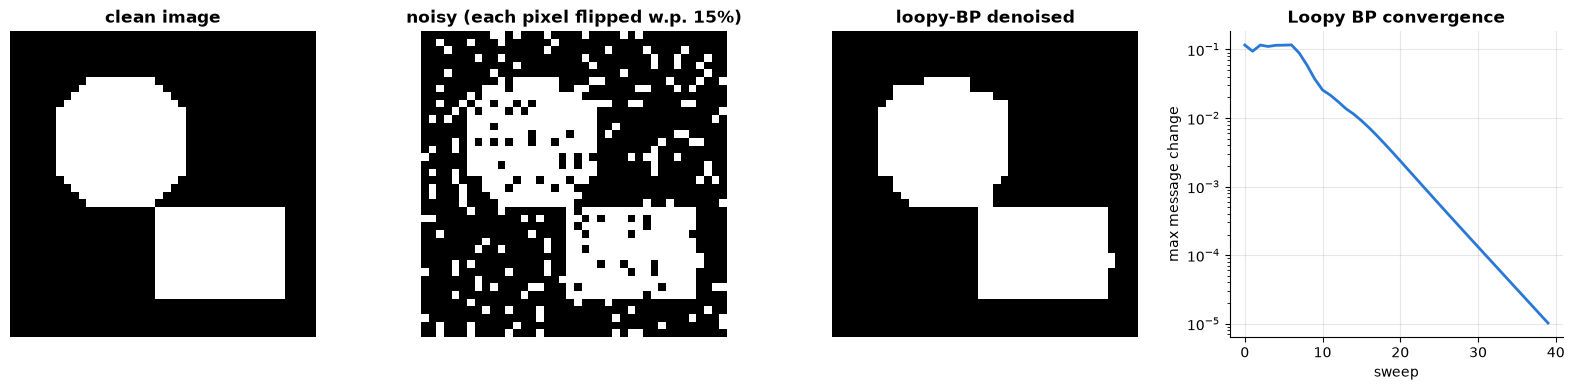

In [11]:
Hh, Ww = 40, 40
yy, xx = np.mgrid[0:Hh, 0:Ww]
clean = np.where(((yy - 14) ** 2 + (xx - 14) ** 2 < 81) | ((yy > 22) & (yy < 35) & (xx > 18) & (xx < 36)), 1, -1)
p_flip = 0.15
noisy = np.where(np.random.default_rng(6).random(clean.shape) < p_flip, -clean, clean)
h_field, J_coupling = 0.5 * np.log((1 - p_flip) / p_flip), 0.8

Ggrid = nx.grid_2d_graph(Hh, Ww)
unary_g = {(i, j): np.exp(h_field * noisy[i, j] * np.array([-1.0, 1.0])) for i, j in Ggrid}   # state 0 -> -1, state 1 -> +1
psi = np.exp(J_coupling * np.array([[1.0, -1.0], [-1.0, 1.0]]))
pair_g = {}
for a, b in Ggrid.edges:
    pair_g[(a, b)] = psi; pair_g[(b, a)] = psi
t0 = time.time()
beliefs_g, deltas_g = pairwise_bp(Ggrid, unary_g, pair_g, iters=40, damping=0.5, tol=1e-6)
denoised = np.array([[1 if beliefs_g[(i, j)][1] > 0.5 else -1 for j in range(Ww)] for i in range(Hh)])
print(f"loopy BP: {len(deltas_g)} sweeps in {time.time() - t0:.1f} s, final max message change = {deltas_g[-1]:.1e}")
print(f"pixel error rate: noisy = {(noisy != clean).mean():.3f}, after loopy BP = {(denoised != clean).mean():.3f}")

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, img, title in [(axes[0], clean, "clean image"), (axes[1], noisy, f"noisy (each pixel flipped w.p. {p_flip:.0%})"),
                       (axes[2], denoised, "loopy-BP denoised")]:
    ax.imshow(img, cmap="gray"); ax.set_title(title); ax.axis("off")
axes[3].semilogy(deltas_g); axes[3].set_xlabel("sweep"); axes[3].set_ylabel("max message change")
axes[3].set_title("Loopy BP convergence"); fig.tight_layout(); plt.show()

**What just happened?** After 40 damped sweeps the messages change by only about $10^{-5}$, and most of the noise is gone: the pixel error rate drops from about 13% (the realised share of flipped pixels) to under 1%. The remaining errors sit mostly at corners and thin parts of the shapes, where the smoothness prior fights the true edges. The $40 \times 40$ grid has treewidth 40, so exact inference would need tables with about $2^{41}$ entries; loopy BP did it with 6,240 small messages per sweep.

🎓 **Exam / interview tip:** "When is BP exact?" On trees (and, for Gaussian models, whenever it converges, for the means). On loopy graphs the fixed points of loopy BP are the stationary points of the **Bethe free energy** (Yedidia, Freeman & Weiss, 2001), which is how it connects to variational inference in the next notebook.

## 6. Max-product and Viterbi: MAP inference

Instead of "how likely is each value?", MAP inference asks "what is the single most likely complete explanation?". Swapping *sum* for *max* in the same algorithms answers it.

The **MAP assignment** is $x^\star = \arg\max_x P(x \mid e)$. Replacing $\sum$ by $\max$ in VE or BP (the **max-product** algorithm, or **max-sum** in log space) computes max-marginals: $\max_{x_{-i}}P(x_i, x_{-i})$ for each value of $x_i$. On a chain this is the **Viterbi algorithm** for HMMs ([`classical_ai/09`](../../00_AI_Fundamentals/classical_ai/09_uncertain_knowledge_and_reasoning.ipynb), [`04_uncommon_models`](../04_uncommon_models/01_uncommon_ml_models.ipynb)):

$$\delta_t(s) = \max_{s'}\big[\delta_{t-1}(s') + \log A_{s's}\big] + \log B_s(o_t), \qquad \text{plus back-pointers}.$$

Cost: $O(TS^2)$ for $T$ steps and $S$ states, against $S^T$ for brute force. Note that the MAP *assignment* is not the same as taking each variable's most likely value from its *marginal*. The two can disagree.

In [12]:
states = ["Sunny", "Cloudy", "Rainy"]; obs_names = ["walk", "shop", "clean"]
pi0 = np.array([0.5, 0.3, 0.2])
A_hmm = np.array([[0.7, 0.2, 0.1], [0.3, 0.4, 0.3], [0.2, 0.3, 0.5]])        # transitions
B_hmm = np.array([[0.7, 0.2, 0.1], [0.3, 0.4, 0.3], [0.1, 0.3, 0.6]])        # emissions P(obs | state)
obs = np.array([0, 1, 1, 1, 2, 1, 1, 0])                                      # walk shop shop shop clean shop shop walk
T_len, S = len(obs), 3

def viterbi(pi0, A, B, obs):
    logd = np.log(pi0) + np.log(B[:, obs[0]]); back = []
    for o in obs[1:]:
        scores = logd[:, None] + np.log(A)                    # scores[prev, cur]
        back.append(scores.argmax(axis=0))
        logd = scores.max(axis=0) + np.log(B[:, o])
    path = [int(logd.argmax())]
    for bp in reversed(back):
        path.append(int(bp[path[-1]]))
    return path[::-1], logd.max()

def forward_prob(pi0, A, B, obs):
    alpha = pi0 * B[:, obs[0]]
    for o in obs[1:]:
        alpha = (alpha @ A) * B[:, o]
    return alpha.sum()

def path_prob(path):
    p = pi0[path[0]] * B_hmm[path[0], obs[0]]
    for t in range(1, T_len):
        p *= A_hmm[path[t - 1], path[t]] * B_hmm[path[t], obs[t]]
    return p

all_paths = list(itertools.product(range(S), repeat=T_len))                    # 3^8 = 6561 paths
probs = np.array([path_prob(p) for p in all_paths])
best_brute = list(all_paths[int(probs.argmax())])
vit_path, vit_logp = viterbi(pi0, A_hmm, B_hmm, obs)
print("observations     :", [obs_names[o] for o in obs])
print("Viterbi MAP path :", [states[s] for s in vit_path], f" P(path, obs) = {np.exp(vit_logp):.3e}")
print("brute force best :", [states[s] for s in best_brute], f" P = {probs.max():.3e}")
print(f"P(obs): forward = {forward_prob(pi0, A_hmm, B_hmm, obs):.6e}, brute-force sum = {probs.sum():.6e}")
assert vit_path == best_brute and np.isclose(forward_prob(pi0, A_hmm, B_hmm, obs), probs.sum())

# The same chain as a pairwise MRF: max-product BP gives the MAP; sum-product gives marginals
chain = nx.path_graph(T_len)
unary_c = {t: B_hmm[:, obs[t]] * (pi0 if t == 0 else 1) for t in range(T_len)}
pair_c = {}
for t in range(T_len - 1):
    pair_c[(t, t + 1)] = A_hmm; pair_c[(t + 1, t)] = A_hmm.T
maxb, _ = pairwise_bp(chain, unary_c, pair_c, mode="max")
sumb, _ = pairwise_bp(chain, unary_c, pair_c, mode="sum")
print("max-product BP   :", [states[int(maxb[t].argmax())] for t in range(T_len)])
marg_path = [int(sumb[t].argmax()) for t in range(T_len)]
print("argmax of each marginal (sum-product):", [states[s] for s in marg_path])
print(f"P(MAP path, obs) = {path_prob(vit_path):.3e}   vs   P(marginal-argmax path, obs) = {path_prob(marg_path):.3e}")

observations     : ['walk', 'shop', 'shop', 'shop', 'clean', 'shop', 'shop', 'walk']
Viterbi MAP path : ['Sunny', 'Sunny', 'Sunny', 'Sunny', 'Sunny', 'Sunny', 'Sunny', 'Sunny']  P(path, obs) = 6.457e-07
brute force best : ['Sunny', 'Sunny', 'Sunny', 'Sunny', 'Sunny', 'Sunny', 'Sunny', 'Sunny']  P = 6.457e-07
P(obs): forward = 1.072580e-04, brute-force sum = 1.072580e-04
max-product BP   : ['Sunny', 'Sunny', 'Sunny', 'Sunny', 'Sunny', 'Sunny', 'Sunny', 'Sunny']
argmax of each marginal (sum-product): ['Sunny', 'Cloudy', 'Cloudy', 'Cloudy', 'Rainy', 'Cloudy', 'Cloudy', 'Sunny']
P(MAP path, obs) = 6.457e-07   vs   P(marginal-argmax path, obs) = 5.202e-07


**What just happened?** Viterbi found the same best path as brute force over all 6,561 paths, and the forward algorithm's $P(\text{obs})$ equals the brute-force sum. Running max-product BP on the chain recovers the same MAP path, showing that Viterbi *is* max-product BP on a chain.

The last two lines show why MAP and marginals answer different questions. The single most probable *sequence* is "Sunny every day": one consistent story that explains every observation reasonably well. Taking each day's most likely state *separately* gives a jumpy Sunny–Cloudy–…–Rainy–…–Sunny sequence, whose joint probability is lower. Each day's marginal sums over many sequences that share that day's state, but the per-day winners do not combine into a likely sequence. Use MAP (Viterbi) when you need one coherent labeling (speech, tagging); use marginals when you need per-position confidence.

## 7. Linear-chain conditional random fields

A CRF is a model that labels a whole sequence at once, scoring each word's features *and* how well neighbouring labels fit together.

An HMM models $P(x, y)$, the words *and* the tags, so it must model how words are generated. Rich, overlapping features such as "capitalised", "suffix -abad" or "previous word is *in*" are awkward there. A **linear-chain conditional random field** (Lafferty, McCallum & Pereira, 2001) models only $P(y \mid x)$:

$$P(y \mid x) = \frac{1}{Z(x)}\exp\Big(\sum_{t}\big[w_{y_t}^\top f(x, t) + T_{y_{t-1}, y_t}\big]\Big), \qquad Z(x) = \sum_{y'}\exp(\text{score}(x, y')).$$

It is an undirected chain over the tags, **conditioned** on the whole input $x$, i.e. multinomial logistic regression over entire label sequences.
- **Inference:** the forward algorithm computes $\log Z(x)$ in $O(TK^2)$ for $K$ tags; forward–backward gives the node and pair marginals; Viterbi gives the best tag sequence.
- **Learning:** the log-likelihood is concave, and its gradient has the classic exponential-family form

$$\frac{\partial \log P(y \mid x)}{\partial w_{k}} = \underbrace{\sum_t f_k(x, t, y_t)}_{\text{observed feature count}} - \underbrace{\mathbb E_{y' \sim P(\cdot\mid x)}\Big[\sum_t f_k(x, t, y'_t)\Big]}_{\text{expected count (from forward–backward)}}.$$

**Toy task.** Tag tokens as `O`, `PER` (person) or `LOC` (location) in template sentences. Test sentences use **names and cities never seen in training**, plus the ambiguous words "Jordan" and "Florence", which can be either. Compare with the spaCy/transformer NER in [`07_NLP/04_named_entity_recognition`](../../07_NLP/04_named_entity_recognition.ipynb).

In [13]:
TAGS = ["O", "PER", "LOC"]; K_TAGS = 3
names_train = ["Alice", "Bilal", "Chen", "Diego", "Fatima", "Hassan", "Ingrid", "Kofi", "Lena", "Omar", "Priya", "Sara"]
names_test = ["Aisha", "Bruno", "Mei", "Tariq", "Yusuf", "Zara"]
cities_train = ["Lahore", "Paris", "Nairobi", "Lima", "Oslo", "Karachi", "Tokyo", "Cairo"]
cities_test = ["Dhaka", "Quito", "Rome", "Accra"]
ambiguous = ["Jordan", "Florence"]                                   # can be a person or a place
templates = ["P lives in L", "P moved to L last year", "P and P met in L", "the conference in L was great",
             "P called P yesterday", "we flew from L to L", "P works for a company in L", "yesterday P visited L",
             "L is a big city", "P is my friend", "my sister P studies in L", "P told me that L is cold"]

def make_sentences(n, names, cities, seed):
    r = np.random.default_rng(seed); data = []
    for _ in range(n):
        words, tags = [], []
        for tok in templates[r.integers(len(templates))].split():
            if tok == "P":
                words.append(str(r.choice(ambiguous) if r.random() < 0.15 else r.choice(names))); tags.append("PER")
            elif tok == "L":
                words.append(str(r.choice(ambiguous) if r.random() < 0.15 else r.choice(cities))); tags.append("LOC")
            else:
                words.append(tok); tags.append("O")
        data.append((words, [TAGS.index(t) for t in tags]))
    return data

train = make_sentences(200, names_train, cities_train, seed=1)
test = make_sentences(80, names_test, cities_test, seed=2)

def token_features(words, t):
    w = words[t]
    return ["bias", "w=" + w.lower(), "suf2=" + w[-2:].lower(), "cap" if w[0].isupper() else "lower",
            "prev=" + (words[t - 1].lower() if t > 0 else "<s>"), "next=" + (words[t + 1].lower() if t + 1 < len(words) else "</s>")]

feat_index = {}
for words, _ in train:
    for t in range(len(words)):
        for f in token_features(words, t):
            feat_index.setdefault(f, len(feat_index))
N_FEAT = len(feat_index)

def featurize(words):
    """Dense 0/1 matrix (tokens x features); features unseen in training are ignored."""
    Xs = np.zeros((len(words), N_FEAT))
    for t in range(len(words)):
        for f in token_features(words, t):
            if f in feat_index:
                Xs[t, feat_index[f]] = 1.0
    return Xs

train_X = [(featurize(w), np.array(y)) for w, y in train]
test_X = [(featurize(w), np.array(y)) for w, y in test]

def group_by_length(data):
    """Stack sentences of equal length into batches so forward-backward runs vectorised over each batch."""
    groups = defaultdict(list)
    for Xs, y in data:
        groups[len(y)].append((Xs, y))
    return [(np.stack([g[0] for g in grp]), np.stack([g[1] for g in grp])) for grp in groups.values()]
train_groups = group_by_length(train_X)
print(f"{len(train)} training / {len(test)} test sentences, {N_FEAT} features; example:", list(zip(*train[0])))

200 training / 80 test sentences, 206 features; example: [('we', 0), ('flew', 0), ('from', 0), ('Oslo', 2), ('to', 0), ('Florence', 2)]


In [14]:
def unpack(theta):
    W = theta[:N_FEAT * K_TAGS].reshape(N_FEAT, K_TAGS)                 # emission weights
    Tr = theta[N_FEAT * K_TAGS:N_FEAT * K_TAGS + K_TAGS**2].reshape(K_TAGS, K_TAGS)   # transition weights
    st = theta[-K_TAGS:]                                                 # start weights
    return W, Tr, st

def lse(a, axis):
    """log(sum(exp(a))) along an axis, computed stably."""
    m = a.max(axis=axis, keepdims=True)
    return (m + np.log(np.exp(a - m).sum(axis=axis, keepdims=True))).squeeze(axis)

def forward_backward(E, Tr, st):
    """Batched log-space forward-backward. E: (B, n, K) emission scores for B sentences of length n.
    Returns log Z (B,), node marginals (B, n, K) and pair marginals (B, n-1, K, K)."""
    n = E.shape[1]
    la = np.zeros_like(E); lb = np.zeros_like(E)
    la[:, 0] = st + E[:, 0]
    for t in range(1, n):                                                # forward pass
        la[:, t] = lse(la[:, t - 1, :, None] + Tr[None], axis=1) + E[:, t]
    for t in range(n - 2, -1, -1):                                       # backward pass
        lb[:, t] = lse(Tr[None] + (E[:, t + 1] + lb[:, t + 1])[:, None, :], axis=2)
    logZ = lse(la[:, -1], axis=1)
    node = np.exp(la + lb - logZ[:, None, None])
    pairs = np.exp(la[:, :-1, :, None] + Tr[None, None] + (E[:, 1:] + lb[:, 1:])[:, :, None, :] - logZ[:, None, None, None])
    return logZ, node, pairs

def nll_and_grad(theta, groups, l2=0.1):
    W, Tr, st = unpack(theta)
    gW, gT, gs = np.zeros_like(W), np.zeros_like(Tr), np.zeros_like(st)
    nll = 0.0
    for Xb, Yb in groups:                                                # Xb: (B, n, F), Yb: (B, n)
        E = Xb @ W
        logZ, node, pairs = forward_backward(E, Tr, st)
        b_idx, t_idx = np.arange(len(Yb))[:, None], np.arange(Yb.shape[1])[None, :]
        score = E[b_idx, t_idx, Yb].sum(1) + Tr[Yb[:, :-1], Yb[:, 1:]].sum(1) + st[Yb[:, 0]]
        nll += (logZ - score).sum()
        onehot = np.eye(K_TAGS)[Yb]
        gW += np.einsum("bnf,bnk->fk", Xb, node - onehot)               # expected minus observed feature counts
        gT += pairs.sum(axis=(0, 1)); np.add.at(gT, (Yb[:, :-1].ravel(), Yb[:, 1:].ravel()), -1)
        gs += (node[:, 0] - onehot[:, 0]).sum(0)
    nll += 0.5 * l2 * (theta @ theta)
    grad = np.concatenate([gW.ravel(), gT.ravel(), gs]) + l2 * theta
    return nll, grad

# gradient check by central finite differences on a few random coordinates
theta0 = np.random.default_rng(7).normal(scale=0.1, size=N_FEAT * K_TAGS + K_TAGS**2 + K_TAGS)
small = group_by_length(train_X[:20])
_, g_analytic = nll_and_grad(theta0, small)
max_rel = 0.0
for k in np.random.default_rng(8).choice(len(theta0), 12, replace=False):
    e = np.zeros_like(theta0); e[k] = 1e-5
    g_num = (nll_and_grad(theta0 + e, small)[0] - nll_and_grad(theta0 - e, small)[0]) / 2e-5
    max_rel = max(max_rel, abs(g_num - g_analytic[k]) / max(1e-8, abs(g_num) + abs(g_analytic[k])))
print(f"gradient check: max relative difference over 12 coordinates = {max_rel:.1e}")
assert max_rel < 1e-5

# log Z check against brute-force enumeration for one sentence
Xs0, y0 = train_X[0]; W0, T0, s0 = unpack(theta0)
brute_logZ = logsumexp([ (Xs0 @ W0)[np.arange(len(y0)), list(ys)].sum() + sum(T0[a, b] for a, b in zip(ys[:-1], ys[1:])) + s0[ys[0]]
                         for ys in itertools.product(range(K_TAGS), repeat=len(y0))])
print(f"log Z: forward algorithm = {forward_backward((Xs0 @ W0)[None], T0, s0)[0][0]:.6f}, brute force = {brute_logZ:.6f}")

gradient check: max relative difference over 12 coordinates = 9.7e-08
log Z: forward algorithm = 6.716928, brute force = 6.716928


In [15]:
t0 = time.time()
res = minimize(nll_and_grad, np.zeros_like(theta0), args=(train_groups,), jac=True, method="L-BFGS-B", options={"maxiter": 300})
W_crf, T_crf, s_crf = unpack(res.x)
print(f"L-BFGS: {res.nit} iterations, {time.time() - t0:.1f} s, final NLL = {res.fun:.2f}")

def crf_viterbi(Xs):
    E = Xs @ W_crf; n = len(E)
    delta = s_crf + E[0]; back = []
    for t in range(1, n):
        sc = delta[:, None] + T_crf
        back.append(sc.argmax(0)); delta = sc.max(0) + E[t]
    path = [int(delta.argmax())]
    for bp in reversed(back):
        path.append(int(bp[path[-1]]))
    return path[::-1]

# baseline: most frequent training tag for each word (unknown words -> O)
word_tag = defaultdict(Counter)
for words, y in train:
    for w, t in zip(words, y):
        word_tag[w][t] += 1
baseline = lambda words: [word_tag[w].most_common(1)[0][0] if w in word_tag else 0 for w in words]

def evaluate(predict):
    stats = Counter()
    for (words, y), (Xs, _) in zip(test, test_X):
        pred = predict(words, Xs)
        for w, t, p in zip(words, y, pred):
            stats["tokens"] += 1; stats["correct"] += t == p
            if t != 0:
                stats["entity"] += 1; stats["entity correct"] += t == p
            if w in ambiguous:
                stats["ambig"] += 1; stats["ambig correct"] += t == p
    return {"token accuracy": stats["correct"] / stats["tokens"], "entity-token accuracy": stats["entity correct"] / stats["entity"],
            "accuracy on Jordan/Florence": stats["ambig correct"] / stats["ambig"]}

crf_scores = pd.DataFrame([{"model": "most-frequent-tag baseline", **evaluate(lambda w, X: baseline(w))},
                           {"model": "linear-chain CRF", **evaluate(lambda w, X: crf_viterbi(X))}]).set_index("model")
print(crf_scores.round(3).to_string())
for words, _ in test[:4]:
    print("  ", " ".join(f"{w}/{TAGS[t]}" for w, t in zip(words, crf_viterbi(featurize(words)))))
trans = pd.DataFrame(T_crf, index=[f"from {t}" for t in TAGS], columns=[f"to {t}" for t in TAGS]).round(2)
trans

L-BFGS: 44 iterations, 0.7 s, final NLL = 11.39
                            token accuracy  entity-token accuracy  accuracy on Jordan/Florence
model                                                                                         
most-frequent-tag baseline           0.692                  0.081                        0.545
linear-chain CRF                     0.993                  0.980                        0.955
   my/O sister/O Bruno/PER studies/O in/O Quito/LOC
   Yusuf/PER moved/O to/O Rome/LOC last/O year/O
   my/O sister/O Aisha/PER studies/O in/O Quito/LOC
   Yusuf/PER works/O for/O a/O company/O in/O Quito/LOC


,to O,to PER,to LOC
from O,0.32,-0.35,0.83
from PER,1.21,-0.40,-0.27
from LOC,-0.41,-0.44,-0.48


**What just happened?**
- **Correctness checks:** the analytic gradient (expected minus observed counts from forward–backward) matches finite differences, and the forward algorithm's $\log Z(x)$ matches brute-force enumeration over all $3^n$ tag sequences.
- **Training:** L-BFGS on the concave log-likelihood converged quickly; sentences of equal length are processed together as one batch.
- **Unseen entities:** the baseline that memorises word → tag can only say `O` for names and cities it has never seen. The CRF generalises through capitalisation and context features ("*lives in* ___", "___ *called*").
- **Ambiguous words:** "Jordan" and "Florence" are tagged from context, which no word-level lookup can do. Both accuracies are high but not perfect: a few ambiguous or weak-context tokens are still mislabelled.
- **Transition weights:** the table shows what the CRF learned about tag order. For example, `LOC → LOC` and `PER → PER` are discouraged, because entities in these templates are single tokens separated by other words.

**Complexity:** forward–backward is $O(nK^2)$ per sentence, and one gradient costs $O(\text{tokens} \times (K^2 + \text{features}))$. A **BiLSTM-CRF** or **transformer-CRF** replaces the hand-made features $f(x, t)$ with neural ones and keeps exactly this CRF layer on top.

## 8. Learning Bayesian networks: parameters and structure

When the network is unknown, we learn its numbers (the CPTs) by counting, and its arrows by searching for the graph that explains the data best without being too complicated.

### 8.1 Parameters from fully observed data

For a BN with complete data, the likelihood **decomposes** into one independent term per CPT row. The **maximum-likelihood estimate** is a ratio of counts:

$$\hat\theta_{x \mid u} = \frac{N(x, u)}{N(u)}.$$

With few data, some counts are 0: probabilities of exactly 0 (a single new case gets probability 0), or even 0/0. **Bayesian estimation with a Dirichlet prior** adds $\alpha$ pseudo-counts to every cell: $\hat\theta_{x\mid u} = \frac{N(x, u) + \alpha}{N(u) + \alpha\,|\mathrm{Val}(X)|}$. With $\alpha = 1$ this is Laplace smoothing.

We use the **student network** (Koller & Friedman, here with binary variables):
- Difficulty (D) and Intelligence (I) → Grade (G);
- I → SAT (S);
- G → Letter (L).

We draw samples by **ancestral sampling** and learn the CPTs back.

In [16]:
student_edges = [("D", "G"), ("I", "G"), ("I", "S"), ("G", "L")]
student_order = ["D", "I", "G", "S", "L"]
student_parents = {v: [u for u, w in student_edges if w == v] for v in student_order}
true_cpt = {"D": {(): 0.4}, "I": {(): 0.3},
            "G": {(0, 0): 0.6, (0, 1): 0.95, (1, 0): 0.2, (1, 1): 0.7},     # P(good grade | D, I)
            "S": {(0,): 0.05, (1,): 0.8}, "L": {(0,): 0.1, (1,): 0.9}}

def ancestral_sample(n, seed):
    r = np.random.default_rng(seed); data = {}
    for v in student_order:                                   # parents are always sampled before children
        pa = student_parents[v]
        p1 = np.array([true_cpt[v][tuple(int(data[u][i]) for u in pa)] for i in range(n)]) if pa else np.full(n, true_cpt[v][()])
        data[v] = (r.random(n) < p1).astype(int)
    return pd.DataFrame(data)

def fit_cpts(df, parents, alpha=0.0):
    est = {}
    for v, pa in parents.items():
        est[v] = {}
        for cfg in itertools.product([0, 1], repeat=len(pa)):
            mask = np.ones(len(df), bool)
            for u, val in zip(pa, cfg):
                mask &= df[u].values == val
            n1, n = df[v].values[mask].sum(), mask.sum()
            est[v][cfg] = (n1 + alpha) / (n + 2 * alpha) if n + 2 * alpha > 0 else np.nan   # nan = 0/0 (no data)
    return est

def cpt_error(est):
    errs = [abs(est[v][cfg] - true_cpt[v][cfg]) for v in true_cpt for cfg in true_cpt[v]]
    return np.nanmean(errs), np.mean([np.isnan(e) for e in errs]), np.mean([est[v][c] in (0.0, 1.0) for v in est for c in est[v]])

rows = []
for n in [10, 30, 100, 300, 1000, 10000]:
    for alpha in [0.0, 1.0]:
        e = [cpt_error(fit_cpts(ancestral_sample(n, seed), student_parents, alpha)) for seed in range(40)]
        rows.append({"N": n, "α": alpha, "mean |θ̂ - θ|": np.mean([x[0] for x in e]),
                     "share of undefined (0/0) entries": np.mean([x[1] for x in e]),
                     "share of entries exactly 0 or 1": np.mean([x[2] for x in e])})
learn_tab = pd.DataFrame(rows)
learn_tab.round(4)

,N,α,mean |θ̂ - θ|,share of undefined (0/0) entries,share of entries exactly 0 or 1
0,10,0.0,0.1572,0.0575,0.4425
1,10,1.0,0.1400,0.0000,0.0000
2,30,0.0,0.0903,0.0000,0.2250
3,30,1.0,0.0804,0.0000,0.0000
4,100,0.0,0.0513,0.0000,0.0450
5,100,1.0,0.0505,0.0000,0.0000
6,300,0.0,0.0287,0.0000,0.0125
7,300,1.0,0.0290,0.0000,0.0000
8,1000,0.0,0.0149,0.0000,0.0000
9,1000,1.0,0.0149,0.0000,0.0000


**What just happened?** With 10 samples, plain maximum likelihood ($\alpha = 0$) leaves some CPT rows undefined: the parent combination never occurred. Many estimates are exactly 0 or 1, which would give probability 0 to perfectly possible cases. Laplace smoothing ($\alpha = 1$) removes both problems and has lower error at small $N$. As $N$ grows, the prior's influence vanishes, both estimators converge to the truth, and the error shrinks like $1/\sqrt N$.

### 8.2 Structure learning by score-based search

To learn the graph itself we search over DAGs for the one with the best **score**. The **BIC score** is log-likelihood minus a complexity penalty:

$$\mathrm{BIC}(G) = \sum_i\Big[\log\hat L_i - \frac{\ln N}{2}\,\#\text{params}_i\Big].$$

It **decomposes** over nodes and their parent sets, so a local move only changes one or two terms. **Greedy hill-climbing**:
1. Start from the empty graph.
2. Repeatedly apply the single edge **addition, deletion or reversal** that most improves BIC while keeping the graph acyclic.
3. Stop at a local optimum.

The alternative family, **constraint-based** methods (PC algorithm), runs conditional-independence tests and orients edges using v-structures.

Data only determine a graph up to its **Markov equivalence class**: graphs with the same skeleton and the same v-structures encode the same independencies. For example, $I \to S$ and $S \to I$ cannot be told apart from data alone, but the collider $D \to G \leftarrow I$ can.

In [17]:
def family_bic(df, v, pa):
    """BIC contribution of node v with parent set pa (binary variables)."""
    N = len(df); ll = 0.0
    keys = df[list(pa)].values if pa else np.zeros((N, 0), int)
    groups = Counter(map(tuple, keys)); ones = Counter(map(tuple, keys[df[v].values == 1]))
    for cfg, n in groups.items():
        n1 = ones.get(cfg, 0); n0 = n - n1
        for c in (n0, n1):
            if c > 0:
                ll += c * np.log(c / n)
    return ll - 0.5 * np.log(N) * (2 ** len(pa))                # one free parameter per parent configuration

def hill_climb_bic(df, start=None, cache=None, max_iter=50):
    nodes = list(df.columns)
    if start is None:
        G = nx.DiGraph(); G.add_nodes_from(nodes)
    else:
        G = start.copy()
    cache = {} if cache is None else cache
    def score(v, graph):
        key = (v, tuple(sorted(graph.predecessors(v))))
        if key not in cache:                                  # BIC decomposes: cache each family's score
            cache[key] = family_bic(df, v, key[1])
        return cache[key]
    history = [sum(score(v, G) for v in nodes)]
    for _ in range(max_iter):
        best_gain, best_move = 1e-9, None
        for a, b in itertools.permutations(nodes, 2):
            moves = []
            if G.has_edge(a, b):
                moves += [("delete", a, b), ("reverse", a, b)]
            elif not G.has_edge(b, a):
                moves += [("add", a, b)]
            for kind, u, w in moves:
                H = G.copy()
                if kind == "add":
                    H.add_edge(u, w)
                elif kind == "delete":
                    H.remove_edge(u, w)
                else:
                    H.remove_edge(u, w); H.add_edge(w, u)
                if not nx.is_directed_acyclic_graph(H):
                    continue
                gain = score(u, H) + score(w, H) - score(u, G) - score(w, G)   # only u's and w's families change
                if gain > best_gain:
                    best_gain, best_move = gain, H
        if best_move is None:
            break
        G = best_move
        history.append(sum(score(v, G) for v in nodes))
    return G, history

def v_structures(G):
    return {(min(a, b), c, max(a, b)) for c in G for a, b in itertools.combinations(G.predecessors(c), 2)
            if not G.has_edge(a, b) and not G.has_edge(b, a)}

def report(name, G, score):
    same_skel = {frozenset(e) for e in G_true.edges()} == {frozenset(e) for e in G.edges()}
    print(f"{name}: BIC = {score:.1f}, edges = {sorted(G.edges())}")
    print(f"   same skeleton as truth: {same_skel} | same v-structures: {v_structures(G) == v_structures(G_true)} "
          f"| v-structures: {v_structures(G) or 'none'}")

df_s = ancestral_sample(5000, seed=11)
G_true = nx.DiGraph(student_edges)
print(f"true graph: BIC = {sum(family_bic(df_s, v, tuple(G_true.predecessors(v))) for v in G_true):.1f}, edges = {sorted(G_true.edges())}")
shared_cache = {}
G_empty, hist = hill_climb_bic(df_s, cache=shared_cache)
report("hill-climbing from the empty graph", G_empty, hist[-1])
print("   BIC after each accepted move:", np.round(hist, 1))

# random restarts: start from random DAGs (random node order, random forward edges) and keep the best result
best_G, best_score = G_empty, hist[-1]
r8 = np.random.default_rng(0)
for restart in range(10):
    order_r = list(r8.permutation(df_s.columns))
    G0 = nx.DiGraph(); G0.add_nodes_from(df_s.columns)
    G0.add_edges_from((order_r[i], order_r[j]) for i, j in itertools.combinations(range(5), 2) if r8.random() < 0.3)
    G_r, h_r = hill_climb_bic(df_s, start=G0, cache=shared_cache)
    if h_r[-1] > best_score + 1e-9:
        best_G, best_score = G_r, h_r[-1]
report("best of 10 random restarts", best_G, best_score)

true graph: BIC = -12247.0, edges = [('D', 'G'), ('G', 'L'), ('I', 'G'), ('I', 'S')]


hill-climbing from the empty graph: BIC = -12250.9, edges = [('D', 'I'), ('G', 'D'), ('G', 'I'), ('G', 'L'), ('I', 'S')]
   same skeleton as truth: False | same v-structures: False | v-structures: none
   BIC after each accepted move: [-16367.  -14584.2 -12989.4 -12614.1 -12295.2 -12250.9]


best of 10 random restarts: BIC = -12247.0, edges = [('D', 'G'), ('G', 'L'), ('I', 'G'), ('S', 'I')]
   same skeleton as truth: True | same v-structures: True | v-structures: {('D', 'G', 'I')}


**What just happened?**
- **From the empty graph**, every accepted move raised the BIC, yet the search got **stuck in a local optimum**. It first linked G to D and to I with arrows pointing *out of* G (no collider), then had to add an extra D–I edge to explain why D and I become dependent once G is known. Its BIC is slightly below the true graph's.
- **With random restarts**, the best run finds a graph with the true graph's BIC, the right **skeleton** and the **v-structure** $D \to G \leftarrow I$. It is in the same Markov equivalence class as the truth. It may still orient a non-collider edge such as $I - S$ or $G - L$ the "other way", which observational data cannot detect.

Greedy search over DAGs is a local search ([`classical_ai/04`](../../00_AI_Fundamentals/classical_ai/04_local_search_and_optimization.ipynb)), so restarts, tabu lists or search over equivalence classes (GES) are standard remedies.

⚠️ **Common mistake:** reading the arrows of a learned BN as causal. Score-based learning finds *a* member of an equivalence class that fits the data. Causal claims need interventions, assumptions such as no hidden confounders, or domain knowledge ([`10_causal_inference`](../10_causal_inference/01_causal_inference.ipynb)).

## 9. Summary table

> 💬 **In plain English:** one table of every inference and learning algorithm here, with its cost and when it is exact.

| Task | Algorithm | Exact? | Cost | Notes |
|---|---|---|---|---|
| marginal / conditional | enumeration | yes | $O(d^n)$ | baseline only |
| marginal / conditional | variable elimination | yes | $O(n\,d^{w+1})$, $w$ = induced width | order matters; min-fill is a good heuristic |
| all marginals, tree | sum-product BP | yes | $O(n\,d^2)$ | two passes |
| all marginals, loopy graph | loopy BP | no | $O(\text{iters}\cdot|E|\,d^2)$ | may not converge; damping helps |
| all marginals, general graph | junction tree | yes | $O(n\,d^{w+1})$ | BP on a tree of cliques |
| MAP | max-product / Viterbi | yes on trees | as sum-product | replace sum by max |
| sequence labelling | linear-chain CRF | yes | $O(nK^2)$ per sentence | discriminative; concave training |
| BN parameters | counts (+ Dirichlet) | closed form | $O(N \cdot n)$ | decomposes per CPT |
| BN structure | BIC hill-climbing | local optimum | many score evaluations | identifies the Markov equivalence class |

Directed vs undirected recap: BNs (local normalisation, causal stories, easy learning) and MRFs/CRFs (symmetric interactions, global $Z$, harder learning). Factor graphs unify both.

## 10. 🔗 How this connects to modern AI

> 💬 **In plain English:** message passing, CRFs and Gibbs distributions live on inside GNNs, NER systems, 5G decoders and diffusion models.

- **Sequence labelling:** CRF output layers on top of BiLSTMs and transformers are still used for NER, slot filling and medical coding when label consistency matters ([`07_NLP/04_named_entity_recognition`](../../07_NLP/04_named_entity_recognition.ipynb)).
- **Message passing everywhere:** graph neural networks are learned, generalised belief propagation ([`05_Deep_Learning/07_gnn`](../../05_Deep_Learning/07_gnn.ipynb)). LDPC decoding in 5G and Wi-Fi is loopy BP. Kalman filters, used in robotics and tracking, are BP for Gaussian chains.
- **Energy-based models and diffusion:** $P(x) \propto e^{-E(x)}$ with an intractable $Z$ is exactly the Gibbs distribution of Section 1. Score-based diffusion models sidestep $Z$ by learning $\nabla_x \log P(x)$, which does not depend on $Z$ ([`05_Deep_Learning/06_generative_models`](../../05_Deep_Learning/06_generative_models.ipynb)).
- **Causal AI and explainability:** Bayesian networks are the backbone of causal graphs and do-calculus ([`10_causal_inference`](../10_causal_inference/01_causal_inference.ipynb)) and of probabilistic expert systems in medicine and fault diagnosis.
- **Structured decoding in LLMs:** beam search and constrained decoding are approximate MAP inference over a chain-structured model; the Viterbi recursion is the exact version for first-order chains ([`08_LLM/17_structured_outputs`](../../08_LLM/17_structured_outputs.ipynb)).
- **Probabilistic programming** (Pyro, NumPyro, Stan) compiles models into factor graphs and runs the inference algorithms of this and the next notebook ([`14_Mathematics/07_bayesian_ml`](../../14_Mathematics/07_bayesian_ml.ipynb)).

## Recap (key takeaways)

- **Bayesian networks** factorise into locally normalised CPTs; **Markov networks** into unnormalised clique potentials with a global **partition function** $Z$. Potentials are not marginals.
- **d-separation** (implemented in linear time by the Bayes-ball reachability algorithm) is *sound*: d-separated ⇒ independent for every compatible distribution. For random (faithful) parameters the converse holds too. The **Markov blanket** (parents, children, co-parents; or neighbours in an MRF) shields a variable from everything else.
- A **factor** library (product, marginalise, reduce) is all exact inference needs.
- **Variable elimination** is exponential only in the **induced width** of the elimination order. **Treewidth** is the best achievable width; min-degree and min-fill are good heuristics. Grids have treewidth equal to their side length.
- **Belief propagation** is exact on trees, $O(n\,d^2)$, and often works well on loopy graphs (image denoising, error-correcting codes) with damping.
- **Max-product / Viterbi** compute MAP assignments, which can differ from per-variable marginal argmaxes.
- **Linear-chain CRFs** model $P(y \mid x)$ with rich features. The likelihood gradient is "observed minus expected feature counts", computed by forward–backward.
- **Learning BNs:** parameters by (smoothed) counting; structure by BIC search, identifiable only up to Markov equivalence.

## Practice problems

**1. (Easy, exam)** For the chain $A \to B \to C$, the fork $A \leftarrow B \to C$ and the collider $A \to B \leftarrow C$, state whether $A \perp C$ and whether $A \perp C \mid B$. Check with code.

<details><summary>Show solution</summary>

Chain and fork: $A \not\perp C$, but $A \perp C \mid B$. Collider: $A \perp C$, but $A \not\perp C \mid B$ (explaining away).

```python
import networkx as nx
chain = nx.DiGraph([("A", "B"), ("B", "C")])
fork = nx.DiGraph([("B", "A"), ("B", "C")])
collider = nx.DiGraph([("A", "B"), ("C", "B")])
for name, G in [("chain A->B->C", chain), ("fork A<-B->C", fork), ("collider A->B<-C", collider)]:
    print(f"{name:18s}: A indep C = {nx.is_d_separator(G, {'A'}, {'C'}, set())}, "
          f"A indep C | B = {nx.is_d_separator(G, {'A'}, {'C'}, {'B'})}")
```

</details>

**2. (Easy, exam)** How many free parameters does a full joint distribution over 10 binary variables need? How many does a chain-structured BN $X_1 \to X_2 \to \dots \to X_{10}$ need?

<details><summary>Show solution</summary>

Full joint: $2^{10} - 1 = 1023$. Chain BN: $1$ for $P(X_1)$, plus $2$ for each of the 9 conditional CPTs ($P(X_i = 1 \mid X_{i-1} = 0)$ and $P(X_i = 1 \mid X_{i-1} = 1)$), giving $1 + 18 = 19$. The graph's missing edges buy a 50-fold reduction, and the gap grows exponentially with $n$.

</details>

**3. (Medium, code)** Compute the induced width of eliminating a $5 \times 5$ grid row by row, and of a random order. Compare with the grid's treewidth (5).

<details><summary>Show solution</summary>

```python
import itertools
import networkx as nx

def induced_width(H, order):
    H = H.copy(); w = 0
    for v in order:
        nb = list(H[v]); w = max(w, len(nb))
        H.add_edges_from(itertools.combinations(nb, 2)); H.remove_node(v)
    return w

k = 5
G = nx.grid_2d_graph(k, k)
row_major = sorted(G.nodes)                                  # eliminate row by row
widths = {"row by row": induced_width(G, row_major)}
r_order = list(G.nodes)
import random; random.Random(0).shuffle(r_order)
widths["random"] = induced_width(G, r_order)
print(widths, "| treewidth of a 5x5 grid is 5")
```
Row-by-row elimination keeps a "frontier" of one row (5 variables) in every intermediate factor, which is optimal for a grid. Random orders usually create much larger cliques.

</details>

**4. (Medium, code)** Implement the HMM forward algorithm and verify $P(\text{observations})$ by brute-force summation over all hidden paths.

<details><summary>Show solution</summary>

```python
import numpy as np, itertools
pi0 = np.array([0.6, 0.4])
A = np.array([[0.8, 0.2], [0.3, 0.7]])
B = np.array([[0.9, 0.1], [0.2, 0.8]])
obs = [0, 1, 1, 0, 1, 1]

def forward(pi0, A, B, obs):
    alpha = pi0 * B[:, obs[0]]
    for o in obs[1:]:
        alpha = (alpha @ A) * B[:, o]
    return alpha.sum()

brute = 0.0
for path in itertools.product(range(2), repeat=len(obs)):
    p = pi0[path[0]] * B[path[0], obs[0]]
    for t in range(1, len(obs)):
        p *= A[path[t - 1], path[t]] * B[path[t], obs[t]]
    brute += p
print(f"forward = {forward(pi0, A, B, obs):.8f}, brute force = {brute:.8f}")
```

</details>

**5. (Medium, code)** In a 4-cycle Markov network $A - B - C - D - A$, show numerically that $P(A \mid B, C, D)$ does not depend on $C$.

<details><summary>Show solution</summary>

In an MRF the Markov blanket is the set of neighbours, here $\{B, D\}$. All factors involving $A$ mention only $A$, $B$ and $D$, so $C$ cancels in $P(A \mid \text{rest})$.

```python
import numpy as np, itertools
# 4-cycle MRF A-B-C-D-A with random pairwise potentials; neighbours of A are B and D
r = np.random.default_rng(3)
pots = {e: r.uniform(0.5, 3, (2, 2)) for e in [(0, 1), (1, 2), (2, 3), (3, 0)]}
P = np.zeros((2, 2, 2, 2))
for x in itertools.product([0, 1], repeat=4):
    P[x] = np.prod([pots[(i, j)][x[i], x[j]] for (i, j) in pots])
P /= P.sum()
cond_A = P[1] / P.sum(axis=0)                        # P(A=1 | B, C, D), shape (2, 2, 2) over (B, C, D)
spread_over_C = np.abs(cond_A[:, 0, :] - cond_A[:, 1, :]).max()
print(f"max change in P(A=1 | B, C, D) when only C changes: {spread_over_C:.2e}  (A's blanket is {{B, D}})")
```

</details>

**6. (Hard, code)** Write the BIC score for a two-variable network and show that, on data generated from $X \to Y$, both $X \to Y$ and $Y \to X$ beat the empty graph and score **exactly the same**. Why?

<details><summary>Show solution</summary>

$X \to Y$ and $Y \to X$ are Markov equivalent: same skeleton, no v-structures. Both are complete graphs on two nodes, so they can represent every joint distribution, have the same number of parameters (3), and reach the same maximum likelihood. BIC cannot tell them apart; only interventions or assumptions can.

```python
import numpy as np, pandas as pd
from collections import Counter

def family_bic(df, v, pa):
    N = len(df); ll = 0.0
    keys = df[list(pa)].values if pa else np.zeros((N, 0), int)
    groups = Counter(map(tuple, keys)); ones = Counter(map(tuple, keys[df[v].values == 1]))
    for cfg, n in groups.items():
        n1 = ones.get(cfg, 0)
        for c in (n - n1, n1):
            if c > 0:
                ll += c * np.log(c / n)
    return ll - 0.5 * np.log(N) * 2 ** len(pa)

# data from X -> Y with a strong dependence
r = np.random.default_rng(0)
x = (r.random(2000) < 0.5).astype(int)
y = np.where(r.random(2000) < 0.85, x, 1 - x)
df = pd.DataFrame({"X": x, "Y": y})
bic_edge = family_bic(df, "X", ()) + family_bic(df, "Y", ("X",))
bic_empty = family_bic(df, "X", ()) + family_bic(df, "Y", ())
bic_rev = family_bic(df, "Y", ()) + family_bic(df, "X", ("Y",))
print(f"BIC  X->Y: {bic_edge:.1f}   Y->X: {bic_rev:.1f}   no edge: {bic_empty:.1f}")
```

</details>

**7. (Hard, conceptual)** Why is belief propagation exact on trees but only approximate on graphs with cycles? What is the treewidth of an $n \times n$ grid, and what does that imply for exact inference on images?

<details><summary>Show solution</summary>

On a tree, removing any node splits the graph into separate subtrees. The message $m_{i \to j}$ summarises *exactly* the subtree behind $i$, and incoming messages are independent pieces of evidence, so their product is correct; the computation is VE with an optimal order. On a loopy graph, evidence can come back around a cycle and be counted more than once, so messages are no longer exact summaries, and BP may oscillate or converge to wrong marginals (fixed points of the Bethe approximation). An $n \times n$ grid has treewidth $n$, so exact inference costs about $d^{n+1}$ per step: for a $256 \times 256$ binary image that is $2^{257}$. Hence the need for approximate methods: loopy BP, graph cuts for MAP, MCMC and variational inference.

</details>

## Further reading (additional learning resources)

- D. Koller and N. Friedman, *Probabilistic Graphical Models: Principles and Techniques*, MIT Press, 2009. Chapters 3–4 (representation, d-separation, Markov networks), 9–10 (variable elimination, clique trees), 11 (loopy BP), 17–18 (parameter and structure learning), 20 (CRF learning).
- C. M. Bishop, *Pattern Recognition and Machine Learning*, Springer, 2006, chapter 8 (graphical models, the sum-product and max-sum algorithms). Free PDF from Microsoft Research.
- C. Sutton and A. McCallum, "An Introduction to Conditional Random Fields", *Foundations and Trends in ML*, 2012. Free on arXiv.
- J. S. Yedidia, W. T. Freeman and Y. Weiss, "Understanding Belief Propagation and its Generalizations", 2001/2003 (the Bethe free energy).
- Stanford CS228 course notes (ermongroup.github.io/cs228-notes), free online.

## Next notebook

Continue with [`02_em_variational_inference_and_sampling.ipynb`](02_em_variational_inference_and_sampling.ipynb), which handles models where exact inference is too expensive or variables are hidden: EM, Gibbs sampling, MCMC diagnostics and variational inference.